# (اسم المشروع- يحتاج نغيره اذا اعتمدنا الاسم) تأمينك
## Deep Learning project

##### Dataset link: https://data.mendeley.com/datasets/5cxyb5fp4f/2$0
## Team members:
* Tarfah Alsunaidi
* Razan
* Aleen
* Layan

## Libraries

In [104]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

## Dataset import

In [105]:
DATA_PATH = 'Motor vehicle insurance data.csv'

df = pd.read_csv(DATA_PATH, sep=';')
display(df.head())
print("Shape:",df.shape)

,ID,Date_start_contract,Date_last_renewal,Date_next_renewal,Date_birth,Date_driving_licence,Distribution_channel,Seniority,Policies_in_force,Max_policies,...,Area,Second_driver,Year_matriculation,Power,Cylinder_capacity,Value_vehicle,N_doors,Type_fuel,Length,Weight
0,1,05/11/2015,05/11/2015,05/11/2016,15/04/1956,20/03/1976,0,4,1,2,...,0,0,2004,80,599,7068.0,0,P,NaN,190
1,1,05/11/2015,05/11/2016,05/11/2017,15/04/1956,20/03/1976,0,4,1,2,...,0,0,2004,80,599,7068.0,0,P,NaN,190
2,1,05/11/2015,05/11/2017,05/11/2018,15/04/1956,20/03/1976,0,4,2,2,...,0,0,2004,80,599,7068.0,0,P,NaN,190
3,1,05/11/2015,05/11/2018,05/11/2019,15/04/1956,20/03/1976,0,4,2,2,...,0,0,2004,80,599,7068.0,0,P,NaN,190
4,2,26/09/2017,26/09/2017,26/09/2018,15/04/1956,20/03/1976,0,4,2,2,...,0,0,2004,80,599,7068.0,0,P,NaN,190


Shape: (105555, 30)


## Data preprocessing

In [106]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105555 entries, 0 to 105554
Data columns (total 30 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   ID                    105555 non-null  int64  
 1   Date_start_contract   105555 non-null  object 
 2   Date_last_renewal     105555 non-null  object 
 3   Date_next_renewal     105555 non-null  object 
 4   Date_birth            105555 non-null  object 
 5   Date_driving_licence  105555 non-null  object 
 6   Distribution_channel  105555 non-null  int64  
 7   Seniority             105555 non-null  int64  
 8   Policies_in_force     105555 non-null  int64  
 9   Max_policies          105555 non-null  int64  
 10  Max_products          105555 non-null  int64  
 11  Lapse                 105555 non-null  int64  
 12  Date_lapse            35147 non-null   object 
 13  Payment               105555 non-null  int64  
 14  Premium               105555 non-null  float64
 15  

In [107]:
df.describe()

,ID,Distribution_channel,Seniority,Policies_in_force,Max_policies,Max_products,Lapse,Payment,Premium,Cost_claims_year,...,Type_risk,Area,Second_driver,Year_matriculation,Power,Cylinder_capacity,Value_vehicle,N_doors,Length,Weight
count,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,...,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,105555.000000,95226.000000,105555.000000
mean,26271.286789,0.451310,6.696604,1.455649,1.837232,1.065842,0.221837,0.319180,315.892557,153.557305,...,2.721804,0.273895,0.123708,2004.728038,92.682611,1617.759367,18413.657243,4.067898,4.252007,1191.262422
std,15388.309324,0.497626,6.263911,0.928427,1.155536,0.267807,0.464858,0.466161,140.927969,1477.112362,...,0.614835,0.445958,0.329250,6.767037,37.012645,604.697382,9135.074235,1.511839,0.393220,458.081834
min,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,40.140000,0.000000,...,1.000000,0.000000,0.000000,1950.000000,0.000000,49.000000,270.460000,0.000000,1.978000,43.000000
25%,12925.000000,0.000000,3.000000,1.000000,1.000000,1.000000,0.000000,0.000000,241.610000,0.000000,...,3.000000,0.000000,0.000000,2001.000000,75.000000,1390.000000,13127.210000,3.000000,3.999000,1043.000000
50%,26082.000000,0.000000,4.000000,1.000000,2.000000,1.000000,0.000000,0.000000,292.280000,0.000000,...,3.000000,0.000000,0.000000,2005.000000,90.000000,1598.000000,17608.770000,5.000000,4.230000,1205.000000
75%,39754.000000,1.000000,9.000000,2.000000,2.000000,1.000000,0.000000,1.000000,361.640000,0.000000,...,3.000000,1.000000,0.000000,2008.000000,110.000000,1910.000000,22595.000000,5.000000,4.443000,1388.000000
max,53502.000000,1.000000,40.000000,17.000000,17.000000,4.000000,7.000000,1.000000,2993.340000,260853.240000,...,4.000000,1.000000,1.000000,2018.000000,580.000000,7480.000000,220675.800000,6.000000,8.218000,7300.000000


### 1. Missing values

In [108]:
df.isnull().sum()

,0
ID,0
Date_start_contract,0
Date_last_renewal,0
Date_next_renewal,0
Date_birth,0
Date_driving_licence,0
Distribution_channel,0
Seniority,0
Policies_in_force,0
Max_policies,0


In [109]:
(df.isnull().sum()/len(df))*100

,0
ID,0.000000
Date_start_contract,0.000000
Date_last_renewal,0.000000
Date_next_renewal,0.000000
Date_birth,0.000000
Date_driving_licence,0.000000
Distribution_channel,0.000000
Seniority,0.000000
Policies_in_force,0.000000
Max_policies,0.000000


- Date_lapse is missing whenever the policy has not lapsed, it is informative not an error.
- Length is missing, impute with the median of the same type risk.
- Type_fuel is missing, will keep it as Unknown.

In [110]:
df['Length_missing'] = df['Length'].isna().astype(int)
df['Length'] = (df['Length']
                .fillna(df.groupby('Type_risk')['Length'].transform('median'))
                .fillna(df['Length'].median()))

In [111]:
df['Type_fuel'] = df['Type_fuel'].fillna('Unknown')

In [112]:
(df.isnull().sum()/len(df))*100

,0
ID,0.000000
Date_start_contract,0.000000
Date_last_renewal,0.000000
Date_next_renewal,0.000000
Date_birth,0.000000
Date_driving_licence,0.000000
Distribution_channel,0.000000
Seniority,0.000000
Policies_in_force,0.000000
Max_policies,0.000000


### 2. Change data type

In [113]:
date_cols = ['Date_start_contract', 'Date_last_renewal', 'Date_next_renewal',
             'Date_birth', 'Date_driving_licence', 'Date_lapse']

for c in date_cols:
    df[c] = pd.to_datetime(df[c], format='%d/%m/%Y', errors='coerce')

### 3. Invalid values

In [114]:
check = {
    'Power == 0':               df.Power == 0,
    'Cylinder_capacity < 50':   df.Cylinder_capacity < 50,
    'Weight < 100 kg':          df.Weight < 100,
    'N_doors == 0':             df.N_doors == 0,
}
display(pd.DataFrame({k: v.groupby(df.Type_risk).sum() for k, v in check.items()}).T
          .rename(columns={1: 'motorbike', 2: 'van', 3: 'car', 4: 'agricultural'}))
print('Power == 0 rows that also have unknown fuel:', ((df.Power == 0) & (df.Type_fuel == 'Unknown')).sum())

# Logical check
age_at_licence = (df.Date_driving_licence - df.Date_birth).dt.days / 365.25
print('\nLicence obtained before age 18:', (age_at_licence < 18).sum())
print('Vehicle registered after the renewal year:', (df.Year_matriculation > df.Date_last_renewal.dt.year).sum())
print('Claims cost > 0 but zero claims:', ((df.Cost_claims_year > 0) & (df.N_claims_year == 0)).sum())

Type_risk,motorbike,van,car,agricultural
Power == 0,1645,0,0,119
Cylinder_capacity < 50,2436,0,0,0
Weight < 100 kg,2833,0,0,0
N_doors == 0,8502,0,0,772


Power == 0 rows that also have unknown fuel: 1764

Licence obtained before age 18: 0
Vehicle registered after the renewal year: 0
Claims cost > 0 but zero claims: 0


- Power == 0 is physically impossible. Handle it as missing and impute with the median power of the same Type_risk.
- N_doors == 0 are all motorbikes/mopeds or agricultural vehicles so they are valid.

In [115]:
df['Power_missing'] = (df['Power'] == 0).astype(int)
df['Power'] = df['Power'].replace(0, np.nan)
df['Power'] = df['Power'].fillna(df.groupby('Type_risk')['Power'].transform('median'))

### 4. Feature engineering

In [116]:
date = df['Date_last_renewal']

df['Age']                 = ((date - df.Date_birth).dt.days / 365.25).round(1)
df['Driving_experience']  = ((date - df.Date_driving_licence).dt.days / 365.25).round(1)
df['Licence_age']         = ((df.Date_driving_licence - df.Date_birth).dt.days / 365.25).round(1)
df['Contract_years']      = ((date - df.Date_start_contract).dt.days / 365.25).round(1)
df['Vehicle_age']         = date.dt.year - df.Year_matriculation
df['Renewal_year']        = date.dt.year
df['Has_claim']           = (df.N_claims_year > 0).astype(int)

df['Vehicle_type'] = df.Type_risk.map({1: 'Motorbike', 2: 'Van', 3: 'Car', 4: 'Agricultural'})

df['Driving_experience'] = df['Driving_experience'].clip(lower=0)
df['Contract_years']     = df['Contract_years'].clip(lower=0)

### 5. Outliers

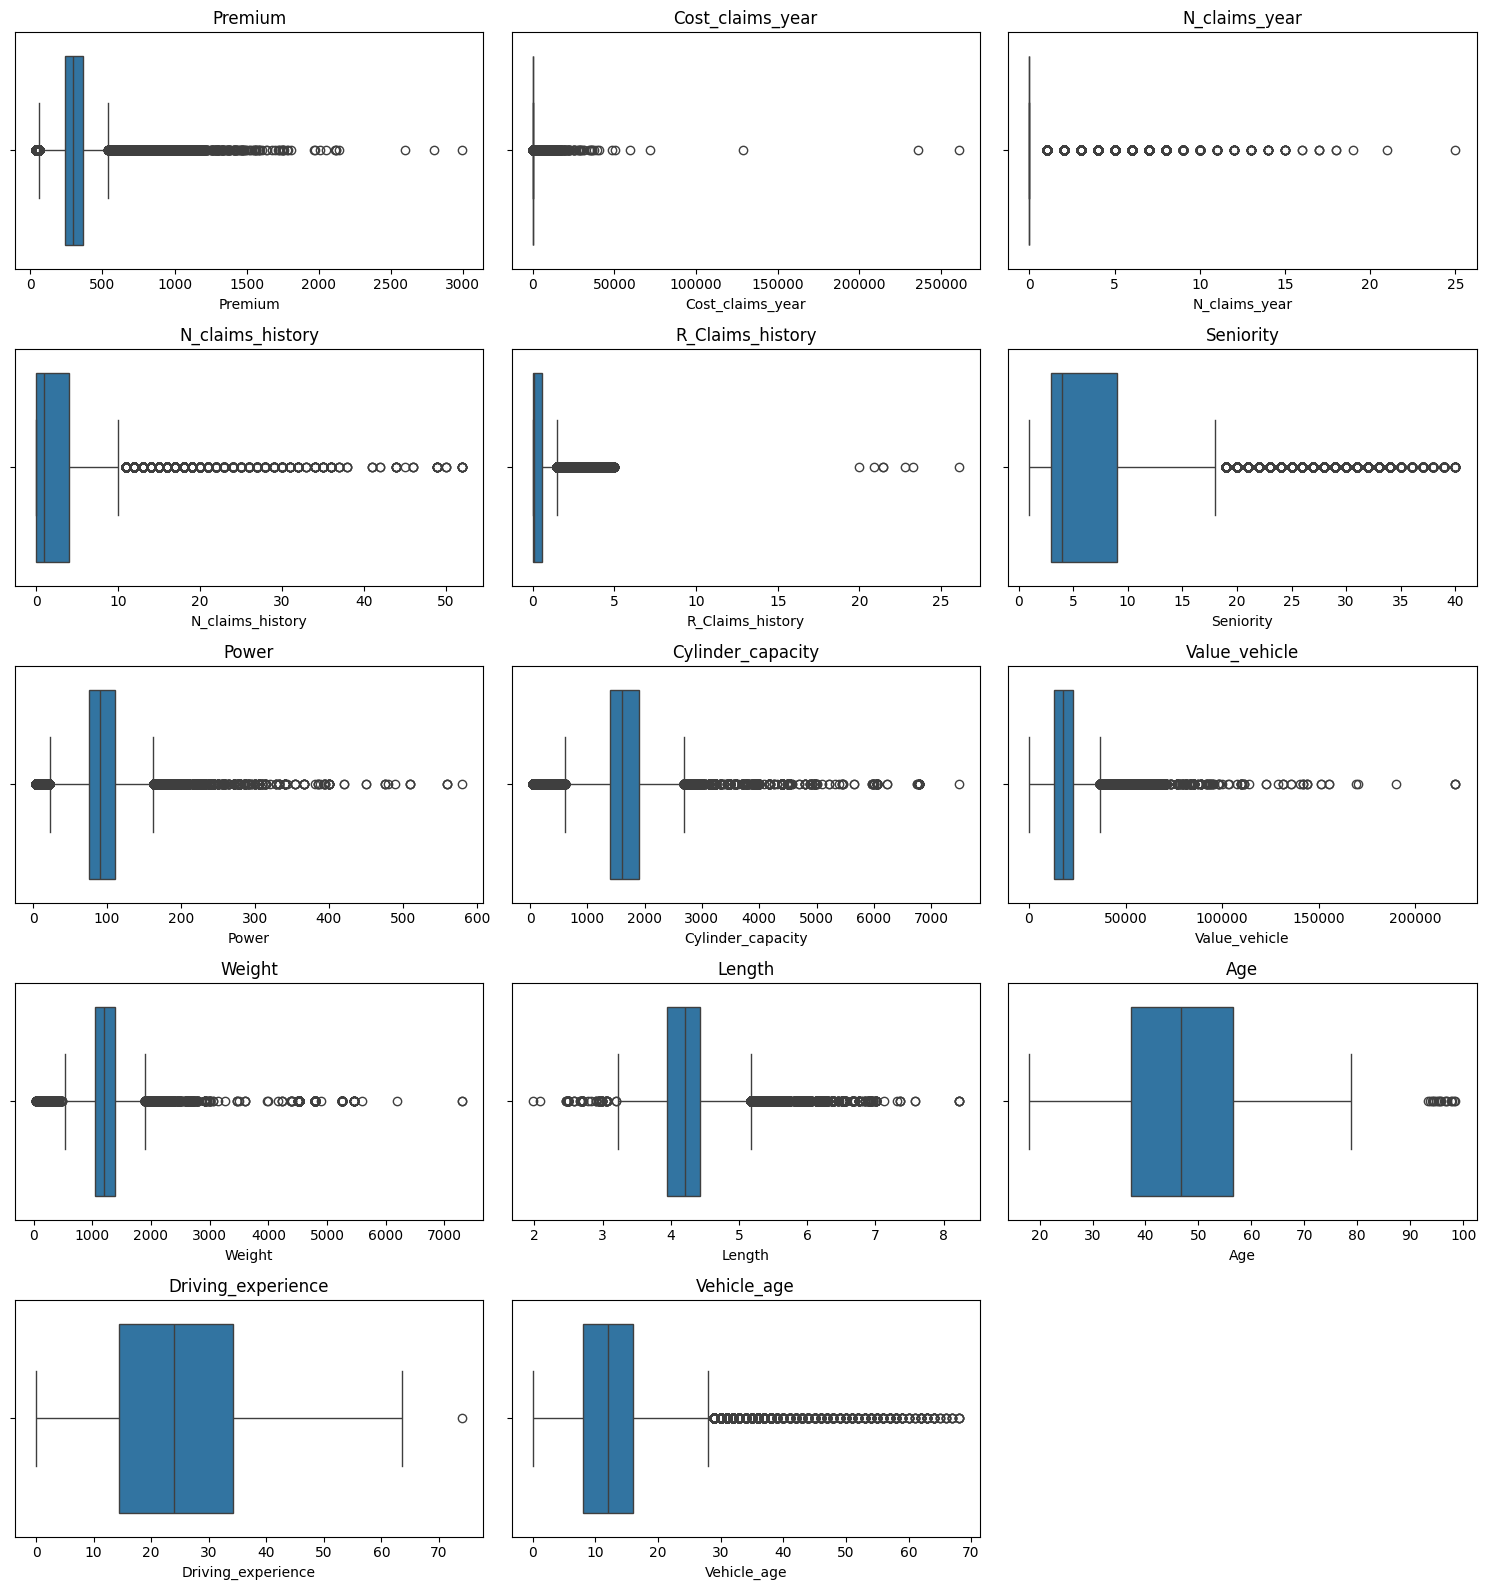

In [117]:
num_cols = ['Premium', 'Cost_claims_year', 'N_claims_year', 'N_claims_history', 'R_Claims_history',
            'Seniority', 'Power', 'Cylinder_capacity', 'Value_vehicle', 'Weight', 'Length',
            'Age', 'Driving_experience', 'Vehicle_age']

fig, axes = plt.subplots(5, 3, figsize=(15, 16))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(num_cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [118]:
#IQR Method
summary = []
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    summary.append([col, lower, upper, n_out, n_out / len(df) * 100])

outliers = pd.DataFrame(summary, columns=['column', 'lower', 'upper', 'n_outliers', '%'])
display(outliers)

,column,lower,upper,n_outliers,%
0,Premium,61.565,541.685,7381,6.992563
1,Cost_claims_year,0.000,0.000,19646,18.612098
2,N_claims_year,0.000,0.000,19646,18.612098
3,N_claims_history,-6.000,10.000,5013,4.749183
4,R_Claims_history,-0.885,1.475,8541,8.091516
5,Seniority,-6.000,18.000,7603,7.202880
6,Power,22.500,162.500,9572,9.068258
7,Cylinder_capacity,610.000,2690.000,10748,10.182369
8,Value_vehicle,-1074.475,36796.685,3344,3.168017
9,Weight,525.500,1905.500,11558,10.949742


In [119]:
#Remove Outliers
cols_to_clean = ['Premium', 'Value_vehicle', 'Age', 'Driving_experience', 'Length']

df_clean = df.copy()
for col in cols_to_clean:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)]

print('Before:', df.shape, ' After:', df_clean.shape)
print(f'Removed {len(df) - len(df_clean):,} rows ({(1 - len(df_clean)/len(df)):.1%})')

Before: (105555, 40)  After: (93401, 40)
Removed 12,154 rows (11.5%)


In [120]:
df_clean.to_csv('insurance_clean.csv', index=False)

## EDA

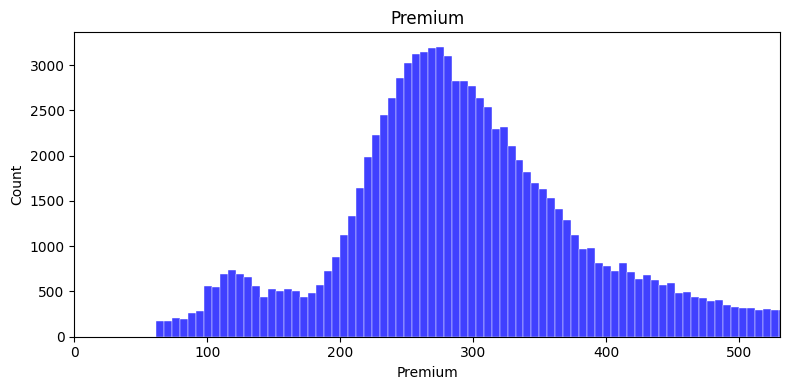

In [121]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df_clean.Premium, bins=80, ax=ax, color='blue', edgecolor='white', linewidth=0.3)
ax.set(title='Premium', xlabel='Premium', xlim=(0, df_clean.Premium.quantile(.995)))
plt.tight_layout()
plt.show()

Most premiums fall between €200 and €400 (median ≈ €284), with fewer policies at higher prices.

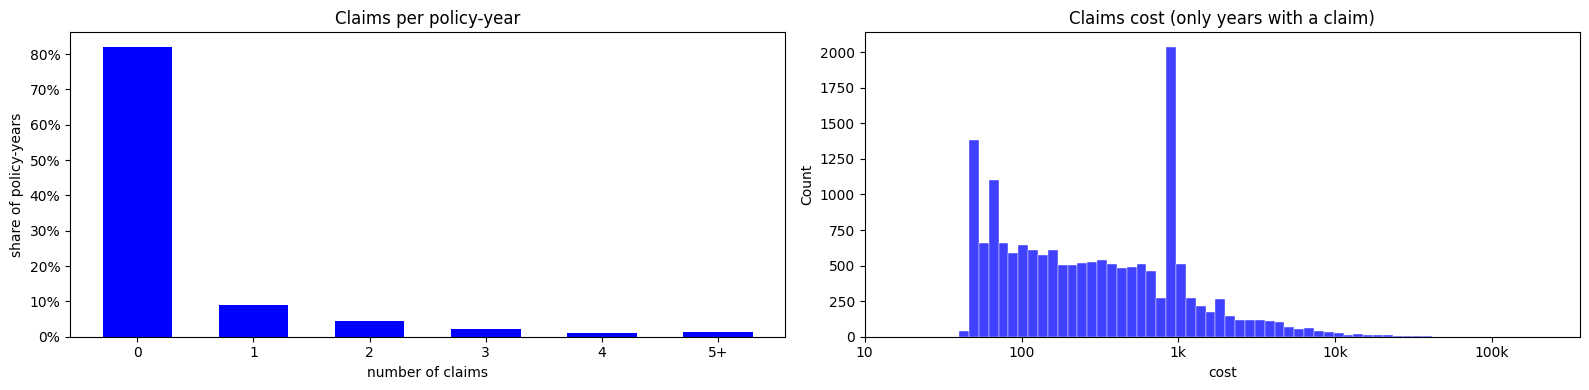

In [122]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))

claims = df_clean.N_claims_year.clip(upper=5).value_counts(normalize=True).sort_index()
claims.index = [str(i) if i < 5 else '5+' for i in claims.index]
ax[0].bar(claims.index, claims.values, color='blue', width=0.6)
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[0].set(title='Claims per policy-year', xlabel='number of claims', ylabel='share of policy-years')

pos = df_clean.loc[df_clean.Cost_claims_year > 0, 'Cost_claims_year']
sns.histplot(np.log10(pos), bins=60, ax=ax[1], color='blue', edgecolor='white', linewidth=0.3)
ax[1].set(title='Claims cost (only years with a claim)', xlabel='cost')
ax[1].set_xticks([1, 2, 3, 4, 5]); ax[1].set_xticklabels(['10', '100', '1k', '10k', '100k'])

plt.tight_layout()
plt.show()

- About 82% of policy-years have no claim, so claims are rare events.
- Most claims cost between €50 and €1,000, with a sharp spike near €900 that suggests a standard fixed payout.

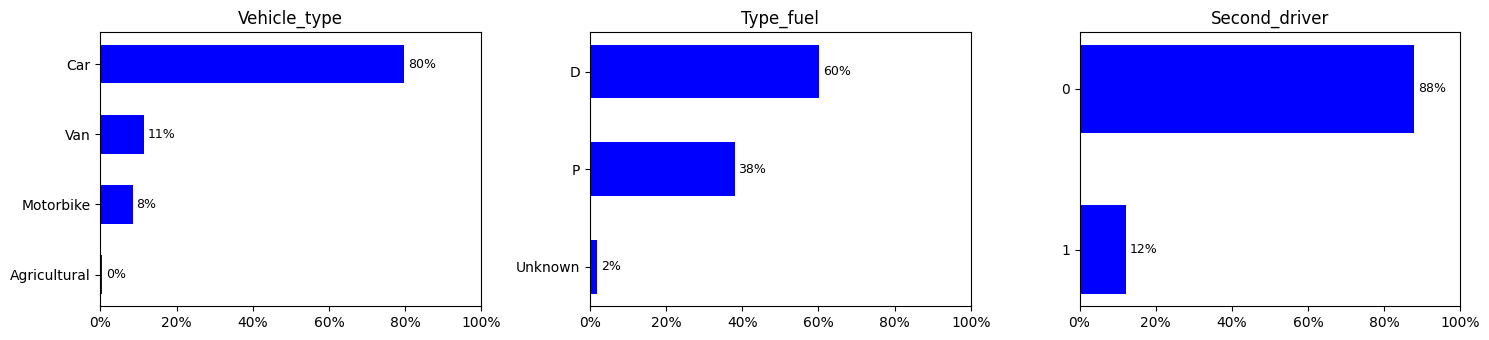

In [123]:
categorical_var = ['Vehicle_type', 'Type_fuel', 'Second_driver']
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, c in zip(axes.ravel(), categorical_var):
    vc = df_clean[c].value_counts(normalize=True)
    ax.barh(vc.index.astype(str), vc.values, color='blue', height=0.55)
    ax.invert_yaxis(); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
    for i, v in enumerate(vc.values): ax.text(v + .01, i, f'{v:.0%}', va='center', fontsize=9)
    ax.set(title=c, xlim=(0, 1))
plt.tight_layout()
plt.show()

The portfolio is mostly cars (80%), mostly diesel (60%), and usually has a single driver (88%).

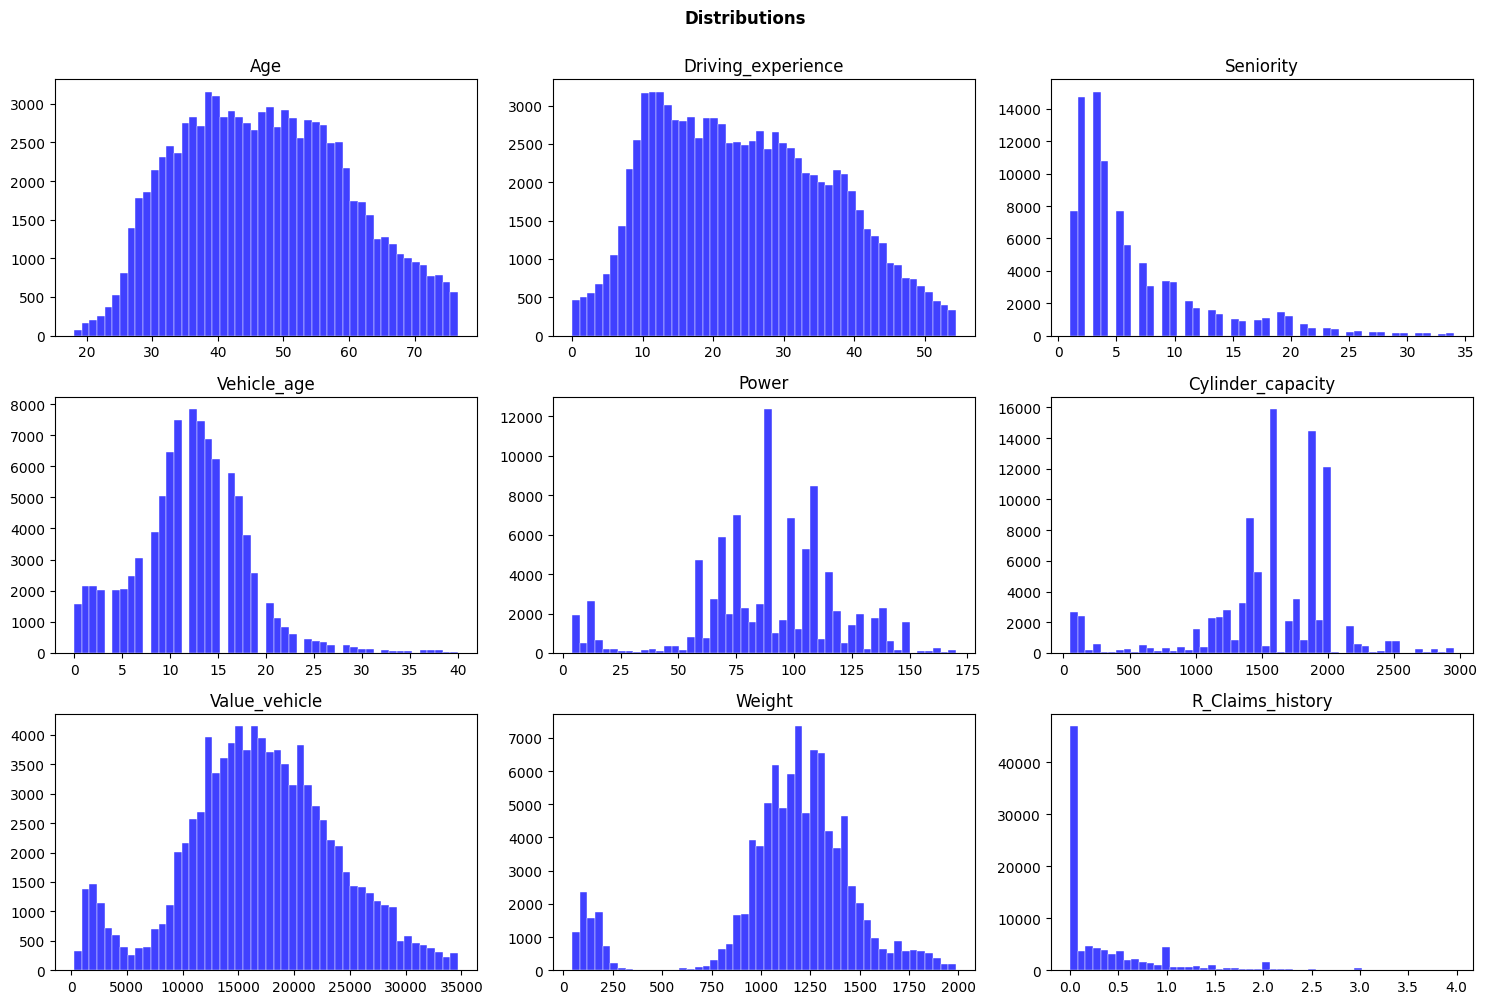

In [124]:
nums = ['Age', 'Driving_experience', 'Seniority', 'Vehicle_age', 'Power',
        'Cylinder_capacity', 'Value_vehicle', 'Weight', 'R_Claims_history']
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), nums):
    upper = df_clean[c].quantile(.995)
    sns.histplot(df_clean.loc[df_clean[c] <= upper, c], bins=50, ax=ax, color='blue', edgecolor='white', linewidth=0.3)
    ax.set(title=c, xlabel='', ylabel='')
fig.suptitle('Distributions', y=1.0, fontweight='bold')
plt.tight_layout(); plt.show()

Most drivers are 30–60 years old with 10–40 years of experience, and most vehicles are 8–17 years old and worth €10k–25k.

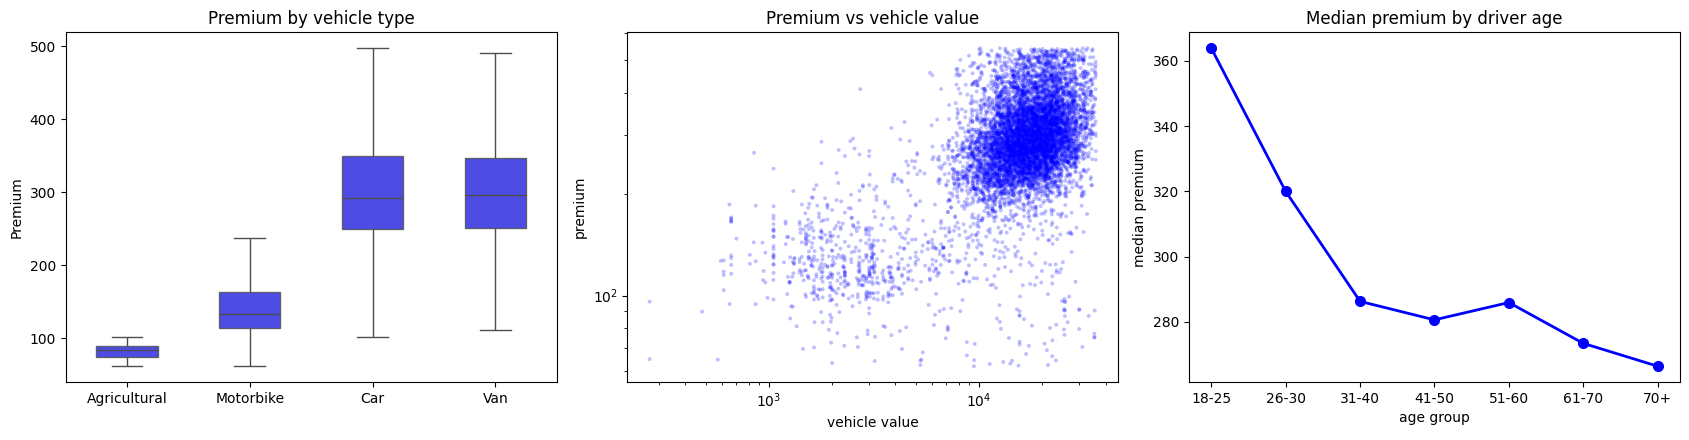

In [125]:
#what effect the premium
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
order = df_clean.groupby('Vehicle_type').Premium.median().sort_values().index
sns.boxplot(data=df_clean, x='Vehicle_type', y='Premium', order=order, ax=ax[0], color='blue',
            showfliers=False, width=.5, boxprops={'alpha': .8})
ax[0].set(title='Premium by vehicle type', xlabel='')

s = df_clean.sample(8000, random_state=0)
ax[1].scatter(s.Value_vehicle, s.Premium, s=8, alpha=.25, color='blue', edgecolor='none')
ax[1].set(xscale='log', yscale='log', title='Premium vs vehicle value',
          xlabel='vehicle value', ylabel='premium')

age_bins = pd.cut(df_clean.Age, [17, 25, 30, 40, 50, 60, 70, 100], labels=['18-25', '26-30', '31-40', '41-50', '51-60', '61-70', '70+'])
p = df_clean.groupby(age_bins, observed=True).Premium.median()
ax[2].plot(p.index.astype(str), p.values, marker='o', color='blue', lw=2, ms=7)
ax[2].set(title='Median premium by driver age', xlabel='age group', ylabel='median premium')
plt.tight_layout(); plt.show()

- Cars and vans pay much higher premiums (≈ €290) than motorbikes (≈ €130) and agricultural vehicles (≈ €85).
- More valuable vehicles tend to pay higher premiums.
- Young drivers (18–25) pay the highest premiums (≈ €364), and premiums fall steadily with age.

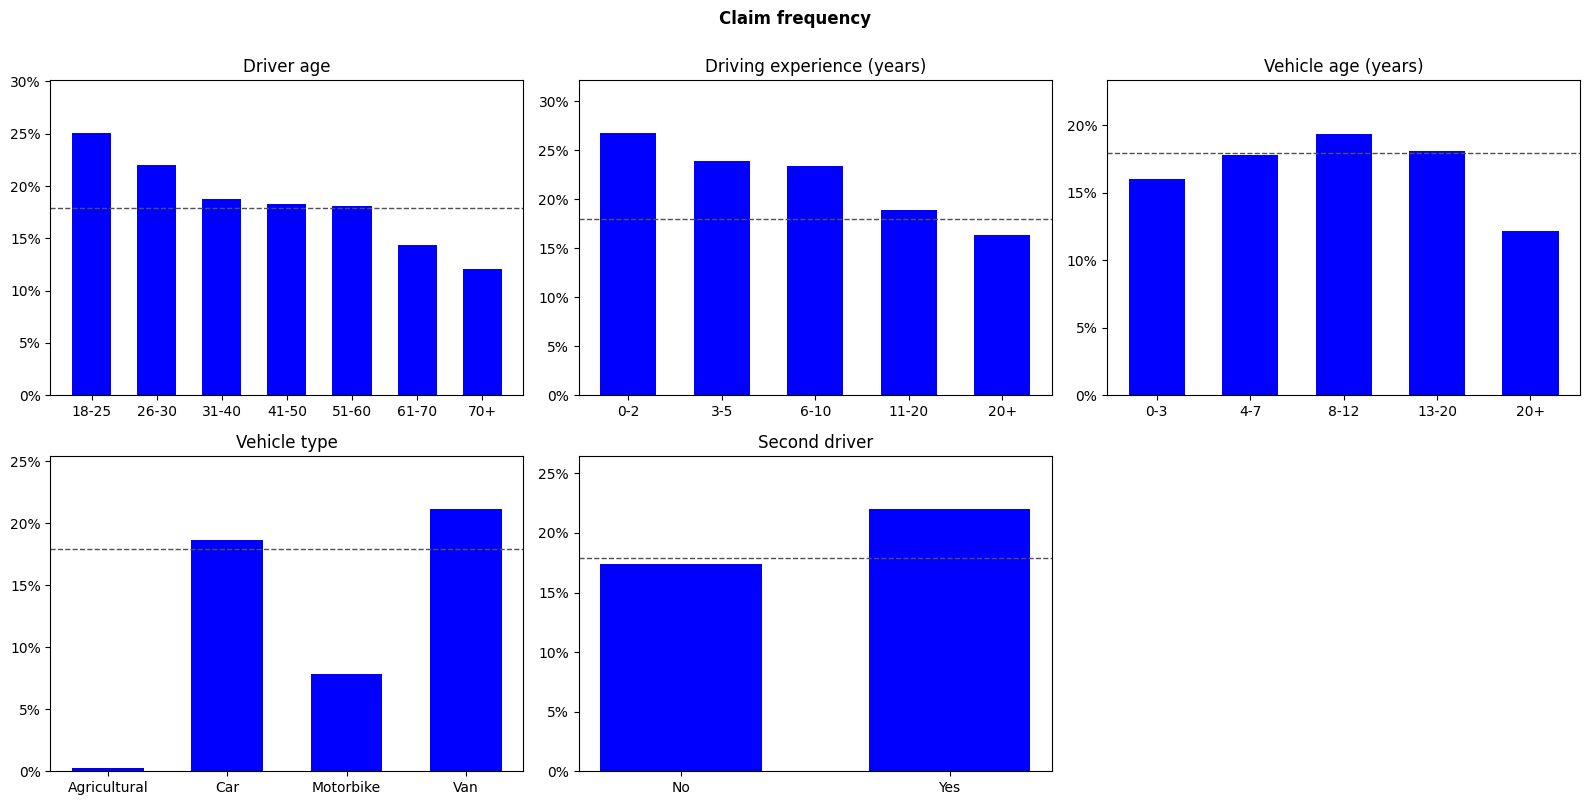

In [126]:
df_clean['Age_group'] = age_bins
df_clean['Vehicle_age_group'] = pd.cut(df_clean.Vehicle_age, [-1, 3, 7, 12, 20, 100], labels=['0-3', '4-7', '8-12', '13-20', '20+'])
df_clean['Experience_group']  = pd.cut(df_clean.Driving_experience, [-1, 2, 5, 10, 20, 100], labels=['0-2', '3-5', '6-10', '11-20', '20+'])

groups = [('Age_group', 'Driver age'), ('Experience_group', 'Driving experience (years)'),
          ('Vehicle_age_group', 'Vehicle age (years)'), ('Vehicle_type', 'Vehicle type'),
          ('Second_driver_label', 'Second driver')]
df_clean['Second_driver_label'] = df_clean.Second_driver.map({0: 'No', 1: 'Yes'})
overall = df_clean.Has_claim.mean()
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (g, t) in zip(axes.ravel(), groups):
    r = df_clean.groupby(g, observed=True).Has_claim.mean()
    ax.bar(r.index.astype(str), r.values, color='blue', width=.6)
    ax.axhline(overall, color='#52514e', ls='--', lw=1)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set(title=t, ylim=(0, max(r.max() * 1.2, overall * 1.3)))

for ax in axes.ravel()[len(groups):]:
    ax.remove()

fig.suptitle('Claim frequency' , fontweight='bold', y=1.0)
plt.tight_layout()
plt.show()

Young and inexperienced drivers claim most (≈ 25–27% vs 12% for drivers over 70), vans claim more than cars and motorbikes (21% vs 19% and 8%), and policies with a second driver claim more (22% vs 17%).

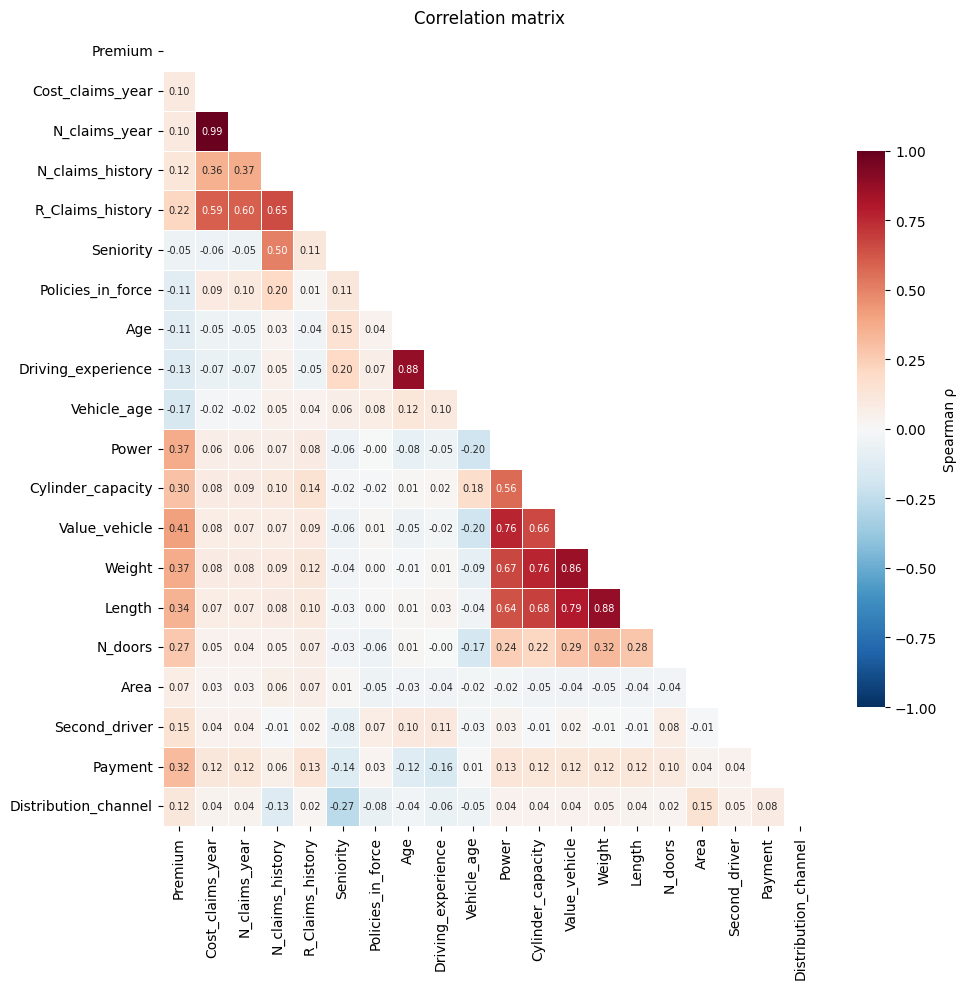

In [127]:
corr_cols = ['Premium', 'Cost_claims_year', 'N_claims_year', 'N_claims_history', 'R_Claims_history',
             'Seniority', 'Policies_in_force', 'Age', 'Driving_experience', 'Vehicle_age',
             'Power', 'Cylinder_capacity', 'Value_vehicle', 'Weight', 'Length', 'N_doors',
             'Area', 'Second_driver', 'Payment', 'Distribution_channel']
corr = df_clean[corr_cols].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 10))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f',
            annot_kws={'size': 7}, linewidths=.5, cbar_kws={'shrink': .7, 'label': 'Spearman ρ'})
plt.title('Correlation matrix'); plt.tight_layout(); plt.show()

Premium is mainly linked to vehicle characteristics (value, power, weight), while several features are almost duplicates (claim cost & count 0.99, weight & length 0.88, age & experience 0.88).